# Q7: Z-Test – Tablet Weight Analysis
**Aim:** To test whether the mean tablet weight differs from 500 mg (σ = 5 mg known).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

### Load dataset (create it if the file is not given)

In [2]:
try:
    df = pd.read_csv("07_Z_Test_Tablet_Weights.csv")
except FileNotFoundError:
    np.random.seed(42)
    df = pd.DataFrame({"Tablet_ID": range(1, 51), "Weight_Mg": np.random.normal(501.5, 5, 50).round(2)})
x = df["Weight_Mg"]
df.head()

,Tablet_ID,Weight_Mg
0,1,503.98
1,2,500.81
2,3,504.74
3,4,509.12
4,5,500.33


### 1. Sample statistics

In [3]:
x.agg(["mean", "median", "std", "var", "min", "max"]).round(3)

,Weight_Mg
mean,500.373
median,500.330
std,4.668
var,21.794
min,491.700
max,510.760


### 2. Hypotheses
- H0: μ = 500 mg
- H1: μ ≠ 500 mg (two-tailed)

### 3 & 4. Z-test at 1% and 5%: Z, p-value, critical values

In [4]:
mu0, sigma, n = 500, 5, len(x)
se = sigma / np.sqrt(n)
z = (x.mean() - mu0) / se
p = 2 * stats.norm.sf(abs(z))
print(f"Sample mean = {x.mean():.3f}, SE = {se:.4f}, Z = {z:.4f}, p-value = {p:.4f}")
for a in [0.05, 0.01]:
    zc = stats.norm.ppf(1 - a / 2)
    print(f"alpha = {a}: critical = ±{zc:.3f} ->", "Reject H0" if abs(z) > zc else "Fail to reject H0")

Sample mean = 500.373, SE = 0.7071, Z = 0.5272, p-value = 0.5980
alpha = 0.05: critical = ±1.960 -> Fail to reject H0
alpha = 0.01: critical = ±2.576 -> Fail to reject H0


### 5. 95% and 99% confidence intervals

In [5]:
for c in [0.95, 0.99]:
    zc = stats.norm.ppf(1 - (1 - c) / 2)
    print(f"{c:.0%} CI: ({x.mean() - zc * se:.3f}, {x.mean() + zc * se:.3f})")

95% CI: (498.987, 501.759)
99% CI: (498.551, 502.194)


If 500 lies outside the interval, H0 is rejected at that level.

### 6. Effect size (Cohen's d)

In [6]:
d = (x.mean() - mu0) / sigma
size = "negligible" if abs(d) < 0.2 else "small" if abs(d) < 0.5 else "medium" if abs(d) < 0.8 else "large"
print(f"Cohen's d = {d:.3f} -> {size} effect")

Cohen's d = 0.075 -> negligible effect


### 7. Histogram with normal curve

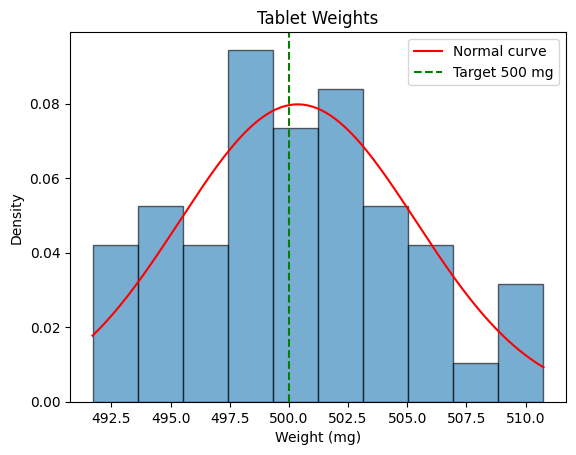

In [7]:
plt.hist(x, bins=10, density=True, alpha=0.6, edgecolor="black")
xs = np.linspace(x.min(), x.max(), 200)
plt.plot(xs, stats.norm.pdf(xs, x.mean(), sigma), color="red", label="Normal curve")
plt.axvline(mu0, color="green", linestyle="--", label="Target 500 mg")
plt.xlabel("Weight (mg)")
plt.ylabel("Density")
plt.title("Tablet Weights")
plt.legend()
plt.show()

### 8. Sample size for a 2 mg difference (power 80%, α = 5%)
 n = ((Z₀.₉₇₅ + Z₀.₈₀) · σ / δ)²

In [8]:
n_req = ((stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * sigma / 2) ** 2
print(f"Required n = {n_req:.2f} -> {int(np.ceil(n_req))} tablets")

Required n = 49.06 -> 50 tablets


**Result:** A two-tailed one-sample Z-test, confidence intervals, effect size and sample size calculation were completed for tablet weights.